### Import

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import sys
from pathlib import Path

ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "paths.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate project root containing src/paths.py")
sys.path.insert(0, str(ROOT))


from src.paths import *
import src.graph_utils as graph_utils
graph_utils = importlib.reload(graph_utils)
rank_candidates = graph_utils.rank_candidates

###  Load Graph Theory metrics

In [2]:
metrics_path = PROCESSED / "graph_theory_metrics.csv"
if metrics_path.is_file():
    metrics = pd.read_csv(metrics_path)
else:
    print(f"Graph metrics are missing: {metrics_path}. Run the graph theory analysis first.")
    metrics = pd.DataFrame(columns=["bus_id", "degree", "betweenness_centrality", "solar_distance_km", "voltage_kv"])

config = __import__("json").load(
    open(CONFIG / "model_config.json")
)

### Rank the candidate locations

In [3]:
candidates = rank_candidates(
    metrics,
    centrality_weight=config["graph"]["centrality_weight"],
    solar_distance_weight=config["graph"]["solar_distance_weight"]
)

# Initial screening assumption: 132 kV and above.
# Review against official CEB connection requirements.
candidates["eligible"] = (
    candidates["voltage_kv"] >= 132
)

display(
    candidates[
        [
            "bus_id",
            "voltage_kv",
            "degree",
            "betweenness_centrality",
            "distance_to_solar_km",
            "site_score",
            "site_cost_factor",
            "eligible"
        ]
    ].head(20)
)

,bus_id,voltage_kv,degree,betweenness_centrality,distance_to_solar_km,site_score,site_cost_factor,eligible
0,BIYAGAMA,220,5,0.364860,11.964151,0.860171,0.783898,True
1,NEW_ANURADHAPURA,220,4,0.266174,0.000000,0.809883,0.814070,True
2,PANNIPITIYA,220,6,0.245115,0.000000,0.785366,0.828780,True
3,KOTMALE,220,5,0.429475,53.306132,0.712155,0.872707,True
4,MONARAGALA,132,3,0.078695,0.000000,0.591617,0.945030,True
5,HAMBANTOTA,220,3,0.073563,0.000000,0.585643,0.948614,True
6,KILINOCHCHI,132,2,0.068966,0.000000,0.580291,0.951826,True
7,KURUNEGALA,132,4,0.047865,0.000000,0.555725,0.966565,True
8,TRINCOMALEE,132,1,0.000000,0.000000,0.500000,1.000000,True
9,VEYANGODA,220,4,0.140969,36.194154,0.468675,1.018795,True


### Visualize the top candidate sites

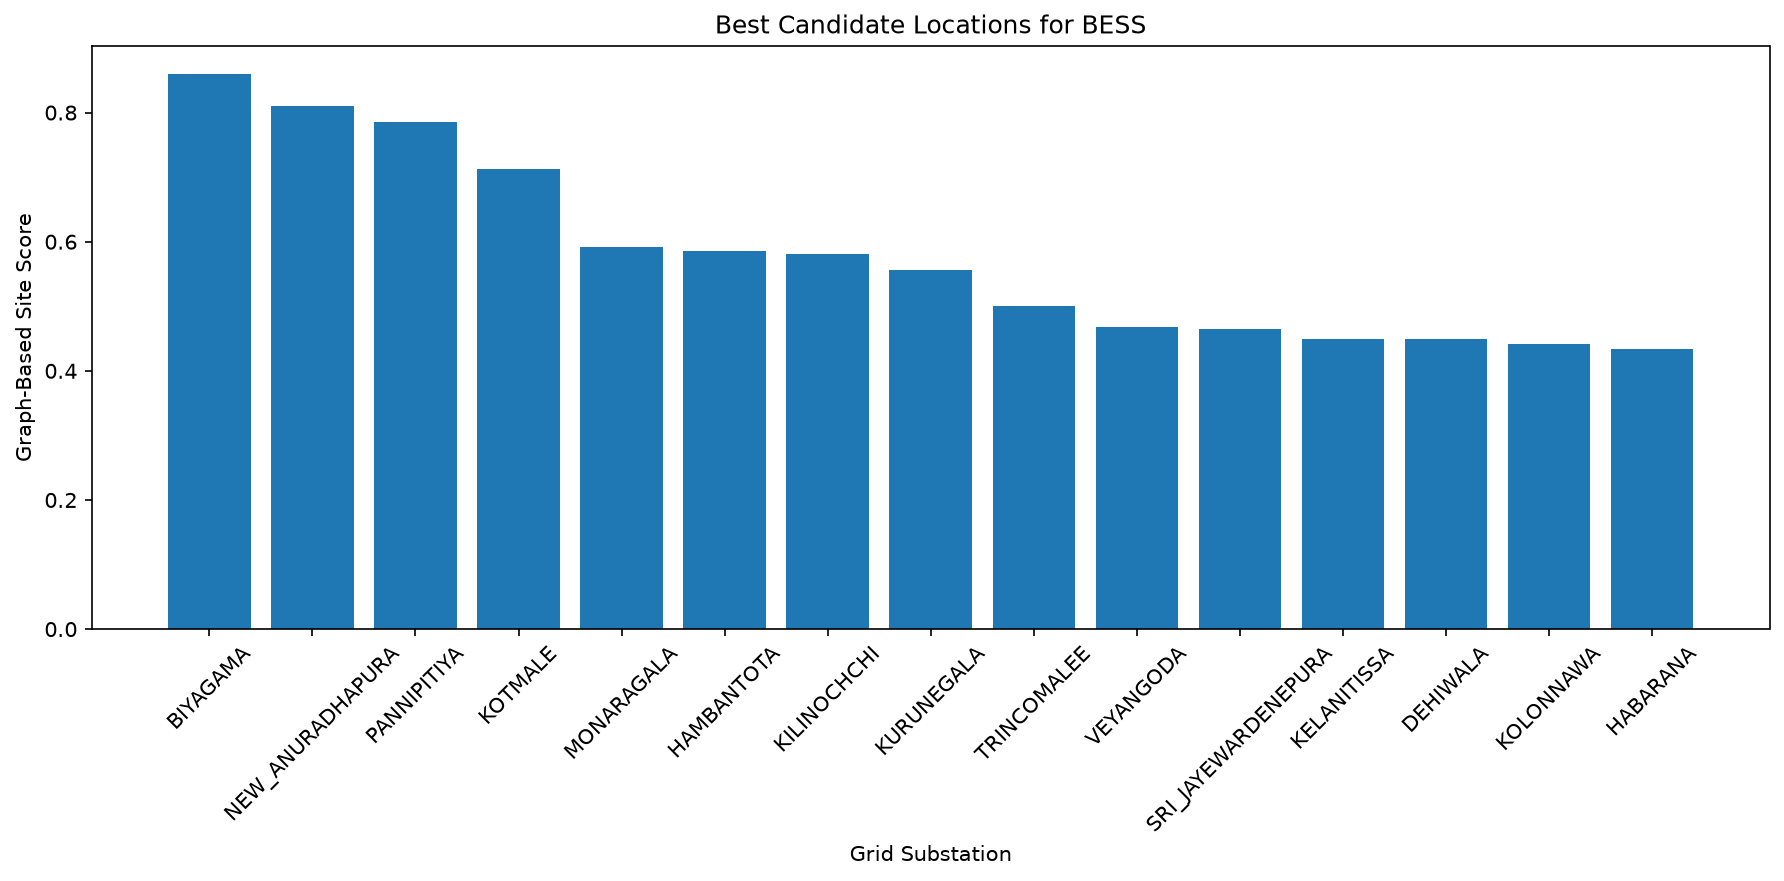

In [4]:
top_sites = candidates[
    candidates["eligible"]
].head(15)

if top_sites.empty:
    print("Candidate site plot skipped: no eligible substations are available.")
else:
    plt.figure(figsize=(12, 6))
    plt.bar(top_sites["bus_id"].astype(str), top_sites["site_score"])
    plt.title("Best Candidate Locations for BESS")
    plt.xlabel("Grid Substation")
    plt.ylabel("Graph-Based Site Score")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(GRAPHS / "candidate_bess_sites.png", dpi=300)
    plt.show()

### Save candidate sites

In [5]:
candidates.to_csv(
    PROCESSED / "candidate_bess_sites.csv",
    index=False
)